# AI Audio: Widziałem dzisiaj Twój głos
Autor rozwiązania: Karol Rejek

Celem pracy jest sprawdzenie, jakie informacje o mowie można odczytać ze spektrogramu i które z nich są najważniejsze dla zachowania zrozumiałości nagrania.

Najpierw analizuję przebieg w czasie, spektrogramy i wybrane cechy sygnału. Następnie stopniowo ograniczam pasmo, zmniejszam liczbę pasm mel i usuwam oryginalną fazę. Wpływ tych zmian sprawdzam przez odsłuch oraz metryki LMD i STOI, a eksperymenty powtarzam na drugiej próbce.

Środowisko: Google Colab

Wykorzystane biblioteki:
- librosa,
- matplotlib
- pystoi

In [1]:
!pip -q install librosa soundfile
import numpy as np
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
from IPython.display import Audio, display
print("librosa:", librosa.__version__)

librosa: 0.11.0


In [2]:
!mkdir -p data && cd data && \
 curl -L https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2 -o lj.tar.bz2 && \
 tar -xjf lj.tar.bz2 --wildcards \
   'LJSpeech-1.1/wavs/LJ001-000[1-5].wav' 'LJSpeech-1.1/metadata.csv' && \
 rm lj.tar.bz2
!ls data/LJSpeech-1.1/wavs

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 2621M  100 2621M    0     0   167M      0  0:00:15  0:00:15 --:--:--  109M
LJ001-0001.wav	LJ001-0002.wav	LJ001-0003.wav	LJ001-0004.wav	LJ001-0005.wav


### Próbki

Do analizy wybrałem trzy nagrania ze zbioru **LJ Speech**: `LJ001-0001`, `LJ001-0002` i `LJ001-0003`. Są to próbki mowy jednej dziewczyny, wczytane jako sygnały mono z częstotliwością próbkowania 22050 Hz.

Krótka próbka `LJ001-0002` (1,90 s) posłużyła do porównania parametrów STFT. Dłuższą `LJ001-0001` (9,66 s) wykorzystałem do analizy cech i degradacji sygnału, a `LJ001-0003` (9,67 s) do sprawdzenia, czy podobne wyniki uzyskam dla innego fragmentu wypowiedzi.

In [3]:
import glob, csv
paths = sorted(glob.glob("data/LJSpeech-1.1/wavs/*.wav"))[:3]

trans = {}
with open("data/LJSpeech-1.1/metadata.csv", encoding="utf-8") as f:
    for row in csv.reader(f, delimiter="|", quoting=csv.QUOTE_NONE):
        trans[row[0]] = row[2]

SR = 22050
signals = {}
for p in paths:
    name = p.split("/")[-1][:-4]
    y, sr = librosa.load(p, sr=SR, mono=True)
    signals[name] = y
    print(f"{name}: {len(y)/sr:.2f} s | sr={sr} | zakres [{y.min():.2f}, {y.max():.2f}]")
    print("  tekst:", trans[name])
    display(Audio(y, rate=sr))

LJ001-0001: 9.66 s | sr=22050 | zakres [-0.68, 0.86]
  tekst: Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition


LJ001-0002: 1.90 s | sr=22050 | zakres [-0.47, 0.50]
  tekst: in being comparatively modern.


LJ001-0003: 9.67 s | sr=22050 | zakres [-0.93, 0.95]
  tekst: For although the Chinese took impressions from wood blocks engraved in relief for centuries before the woodcutters of the Netherlands, by a similar process


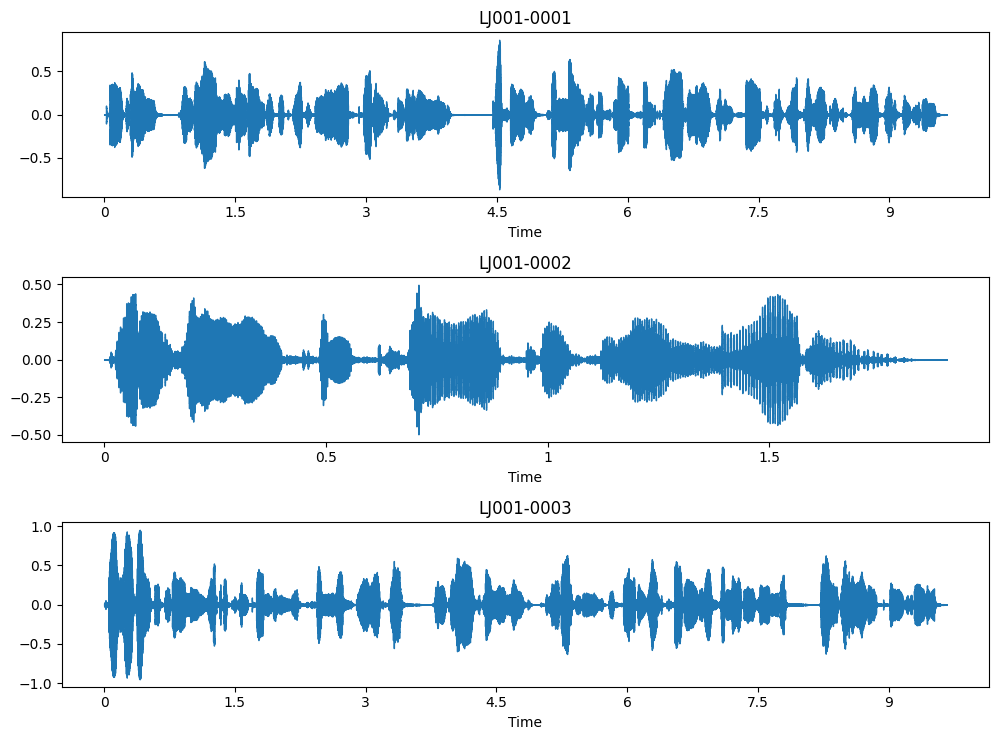

In [4]:
fig, axs = plt.subplots(len(signals), 1, figsize=(10, 2.5*len(signals)))
for ax, (n, y) in zip(np.atleast_1d(axs), signals.items()):
    librosa.display.waveshow(y, sr=SR, ax=ax)
    ax.set_title(n)
plt.tight_layout(); plt.show()

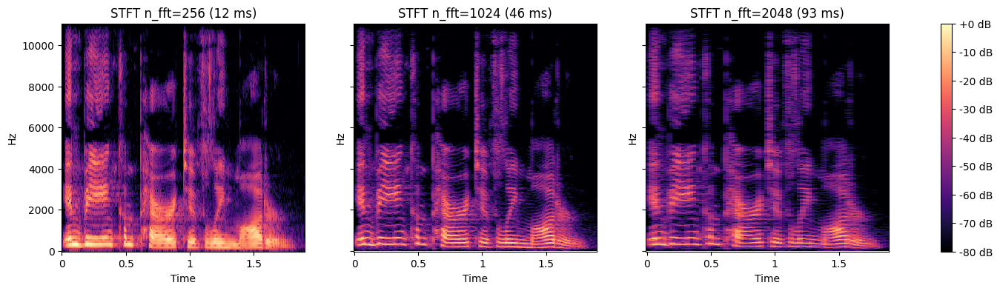

In [5]:
name = "LJ001-0002"
y = signals[name]

fig, axs = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, n_fft in zip(axs, [256, 1024, 2048]):
    D = librosa.stft(y, n_fft=n_fft, hop_length=n_fft//4)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    img = librosa.display.specshow(S_db, sr=SR, hop_length=n_fft//4,
                                   x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(f"STFT n_fft={n_fft} ({n_fft/SR*1000:.0f} ms)")
fig.colorbar(img, ax=axs, format="%+2.0f dB")
plt.show()

### Wnioski z przebiegu w czasie i spektrogramu

Przebieg w czasie pokazuje zmiany amplitudy i pauzy, natomiast spektrogram pozwala prześledzić rozkład częstotliwości. Widać na nim harmoniczne i zmiany intonacji oraz fragmenty szumowe bez wyraźnej struktury harmonicznej. Nie zawiera on informacji o fazie, a względna skala dB nie pozwala określić bezwzględnej głośności.

Do dalszej analizy wybrałem **n_fft=1024 i hop=256** jako kompromis między rozdzielczością czasową i częstotliwościową. Spektrogram mel upraszcza reprezentację z 513 do 80 wartości na ramkę, kosztem utraty części szczegółów widma.

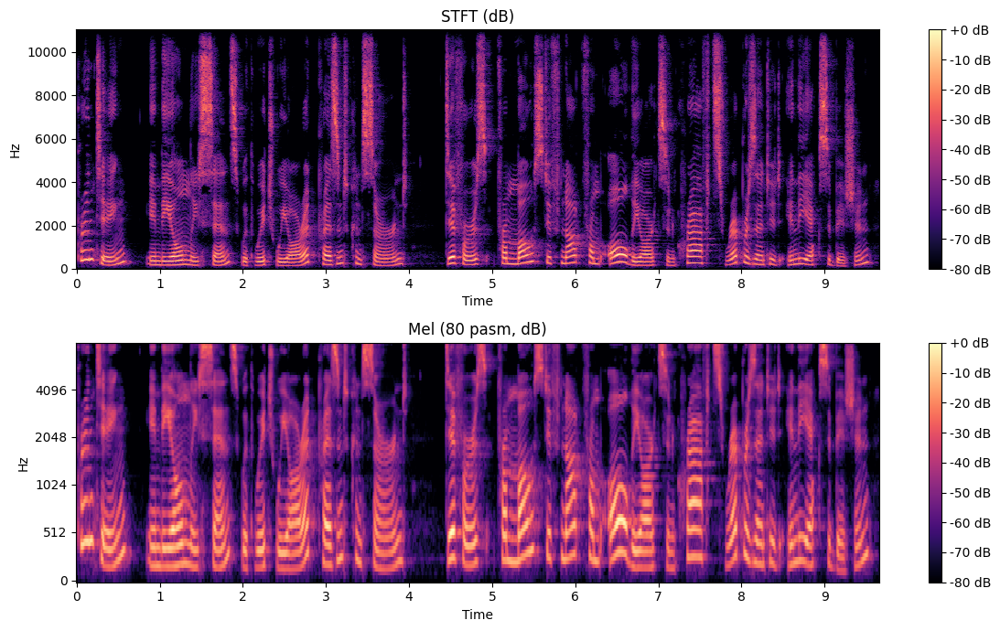

STFT: (513, 832) | Mel: (80, 832)


In [6]:
N_FFT, HOP = 1024, 256
y = signals["LJ001-0001"]

D = librosa.stft(y, n_fft=N_FFT, hop_length=HOP)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

M = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=80, fmax=8000)
M_db = librosa.power_to_db(M, ref=np.max)

fig, axs = plt.subplots(2, 1, figsize=(12, 7))
im1 = librosa.display.specshow(S_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="hz", ax=axs[0])
axs[0].set_title("STFT (dB)"); fig.colorbar(im1, ax=axs[0], format="%+2.0f dB")
im2 = librosa.display.specshow(M_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", fmax=8000, ax=axs[1])
axs[1].set_title("Mel (80 pasm, dB)"); fig.colorbar(im2, ax=axs[1], format="%+2.0f dB")
plt.tight_layout(); plt.show()
print("STFT:", S_db.shape, "| Mel:", M_db.shape)

In [7]:
name = "LJ001-0001"
y = signals[name]
N_FFT, HOP = 1024, 256

f0, voiced_flag, voiced_prob = librosa.pyin(
    y, fmin=librosa.note_to_hz("C2"), fmax=librosa.note_to_hz("C6"),
    sr=SR, frame_length=2048, hop_length=HOP)

mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=80, fmax=8000)
mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel), n_mfcc=13)

rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP)[0]

centroid = librosa.feature.spectral_centroid(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP)[0]
rolloff = librosa.feature.spectral_rolloff(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, roll_percent=0.85)[0]

times_f0 = librosa.times_like(f0, sr=SR, hop_length=HOP)
times = librosa.times_like(rms, sr=SR, hop_length=HOP)

print("Ramki: f0", f0.shape, "| mfcc", mfcc.shape, "| rms", rms.shape, "| centroid", centroid.shape)
print(f"Dźwięczne ramki: {np.nanmean(voiced_flag)*100:.1f}%")
print(f"F0: średnia {np.nanmean(f0):.1f} Hz, min {np.nanmin(f0):.1f}, max {np.nanmax(f0):.1f}")

Ramki: f0 (832,) | mfcc (13, 832) | rms (832,) | centroid (832,)
Dźwięczne ramki: 74.4%
F0: średnia 234.1 Hz, min 133.9, max 458.2


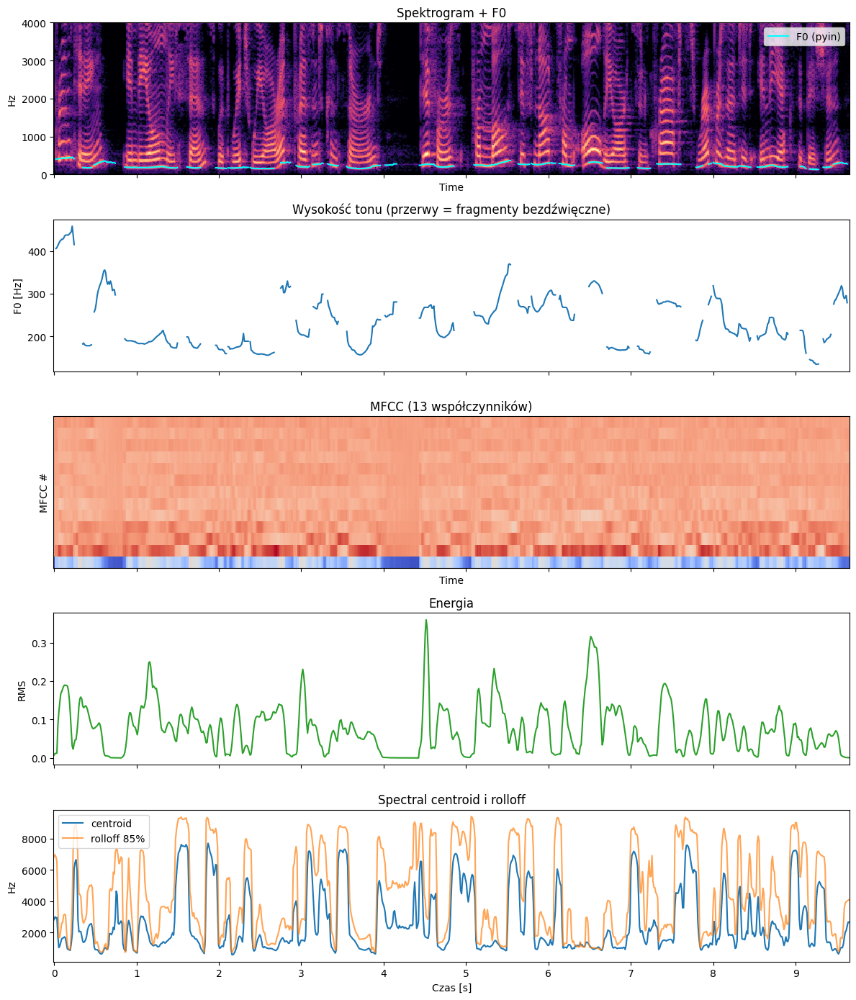

In [8]:
S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP)), ref=np.max)

fig, axs = plt.subplots(5, 1, figsize=(12, 14), sharex=True)

librosa.display.specshow(S_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="hz", ax=axs[0])
axs[0].plot(times_f0, f0, color="cyan", lw=1.5, label="F0 (pyin)")
axs[0].set_ylim(0, 4000); axs[0].legend(loc="upper right"); axs[0].set_title("Spektrogram + F0")

axs[1].plot(times_f0, f0, color="tab:blue"); axs[1].set_ylabel("F0 [Hz]")
axs[1].set_title("Wysokość tonu (przerwy = fragmenty bezdźwięczne)")

librosa.display.specshow(mfcc, sr=SR, hop_length=HOP, x_axis="time", ax=axs[2])
axs[2].set_ylabel("MFCC #"); axs[2].set_title("MFCC (13 współczynników)")

axs[3].plot(times, rms, color="tab:green"); axs[3].set_ylabel("RMS")
axs[3].set_title("Energia")

axs[4].plot(times, centroid, label="centroid"); axs[4].plot(times, rolloff, label="rolloff 85%", alpha=0.7)
axs[4].set_ylabel("Hz"); axs[4].legend(); axs[4].set_title("Spectral centroid i rolloff")
axs[4].set_xlabel("Czas [s]")

plt.tight_layout(); plt.show()

### Wnioski z analizy cech

Średnie F0 wyniosło 234,1 Hz, a algorytm zaklasyfikował 74,4% ramek jako dźwięczne. Przebieg F0 pozwala śledzić intonację, natomiast MFCC opisują kształt obwiedni widmowej, istotny dla rozpoznawania mowy.

W aktywnych fragmentach bezdźwięcznych centroid był wyższy niż w dźwięcznych (4788 wobec 1952 Hz), podobnie jak rolloff (6430 wobec 3498 Hz). Wskazuje to na większy udział wysokich częstotliwości. Różnica RMS była mniejsza (0,080 wobec 0,099), dlatego sama amplituda nie wystarcza do rozróżnienia tych fragmentów. Najwięcej informacji daje łączne wykorzystanie cech opisujących ton, widmo i zmiany amplitudy.

In [9]:
n = min(len(voiced_flag), len(rms), len(centroid))
v = voiced_flag[:n].astype(bool)
active = rms[:n] > 0.02

stats = {
    "RMS":      (rms[:n][v & active].mean(),      rms[:n][~v & active].mean()),
    "Centroid [Hz]": (centroid[:n][v & active].mean(), centroid[:n][~v & active].mean()),
    "Rolloff [Hz]":  (rolloff[:n][v & active].mean(),  rolloff[:n][~v & active].mean()),
}
print(f"{'cecha':16s}{'dźwięczne':>12s}{'bezdźwięczne':>14s}")
for k, (a, b) in stats.items():
    print(f"{k:16s}{a:12.3f}{b:14.3f}")

cecha              dźwięczne  bezdźwięczne
RMS                    0.099         0.080
Centroid [Hz]       1952.145      4787.809
Rolloff [Hz]        3497.667      6429.994


In [12]:
import pandas as pd

y = signals["LJ001-0001"]
N_FFT, HOP = 1024, 256
results = []

def logmel(x, n_mels=80):
    M = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=n_mels, fmax=8000)
    return librosa.power_to_db(M, ref=1.0, top_db=80.0)

REF = logmel(y)

def lmd(x):
    n = min(REF.shape[1], logmel(x).shape[1])
    return float(np.mean(np.abs(REF[:, :n] - logmel(x)[:, :n])))

def report(group, level, x, size):
    d = lmd(x)
    results.append({"degradacja": group, "poziom": level, "liczba wartości/ramkę": size, "LMD [dB]": round(d, 2)})
    print(f"{group} | {level} | LMD = {d:.2f} dB")
    display(Audio(x, rate=SR))

D = librosa.stft(y, n_fft=N_FFT, hop_length=HOP)
report("referencja", "oryginał", y, D.shape[0])

referencja | oryginał | LMD = 0.00 dB


In [13]:
freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
for fc in [8000, 6000, 4000, 2000, 1000]:
    mask = freqs <= fc
    D_cut = D * mask[:, None]
    x = librosa.istft(D_cut, hop_length=HOP, n_fft=N_FFT, length=len(y))
    report("1. obcięcie pasma", f"{fc} Hz", x, int(mask.sum()))

1. obcięcie pasma | 8000 Hz | LMD = 0.00 dB


1. obcięcie pasma | 6000 Hz | LMD = 1.26 dB


1. obcięcie pasma | 4000 Hz | LMD = 3.52 dB


1. obcięcie pasma | 2000 Hz | LMD = 8.18 dB


1. obcięcie pasma | 1000 Hz | LMD = 12.99 dB


In [14]:
mag = np.abs(D)
x_gl = librosa.griffinlim(mag, n_iter=32, hop_length=HOP, n_fft=N_FFT, length=len(y))
report("2. redukcja mel", "odniesienie: pełne STFT + GL", x_gl, D.shape[0])

for nm in [128, 80, 40, 20, 10]:
    M = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=nm)
    x = librosa.feature.inverse.mel_to_audio(M, sr=SR, n_fft=N_FFT, hop_length=HOP, n_iter=32, length=len(y))
    report("2. redukcja mel", f"{nm} pasm", x, nm)

2. redukcja mel | odniesienie: pełne STFT + GL | LMD = 0.36 dB


2. redukcja mel | 128 pasm | LMD = 1.10 dB


2. redukcja mel | 80 pasm | LMD = 2.11 dB


2. redukcja mel | 40 pasm | LMD = 3.80 dB


2. redukcja mel | 20 pasm | LMD = 6.80 dB


2. redukcja mel | 10 pasm | LMD = 9.64 dB


In [15]:
rng = np.random.default_rng(0)
x = librosa.istft(mag * np.exp(1j * rng.uniform(-np.pi, np.pi, mag.shape)), hop_length=HOP, n_fft=N_FFT, length=len(y))
report("3. usunięcie fazy", "faza losowa", x, D.shape[0])

x = librosa.istft(mag.astype(complex), hop_length=HOP, n_fft=N_FFT, length=len(y))
report("3. usunięcie fazy", "faza zerowa", x, D.shape[0])

for it in [1, 4, 16, 64]:
    x = librosa.griffinlim(mag, n_iter=it, hop_length=HOP, n_fft=N_FFT, length=len(y))
    report("3. usunięcie fazy", f"Griffin-Lim {it} iter.", x, D.shape[0])

3. usunięcie fazy | faza losowa | LMD = 5.39 dB


3. usunięcie fazy | faza zerowa | LMD = 15.24 dB


3. usunięcie fazy | Griffin-Lim 1 iter. | LMD = 2.05 dB


3. usunięcie fazy | Griffin-Lim 4 iter. | LMD = 1.19 dB


3. usunięcie fazy | Griffin-Lim 16 iter. | LMD = 0.56 dB


3. usunięcie fazy | Griffin-Lim 64 iter. | LMD = 0.25 dB


,degradacja,poziom,liczba wartości/ramkę,LMD [dB]
0,referencja,oryginał,513,0.00
1,1. obcięcie pasma,8000 Hz,372,0.00
2,1. obcięcie pasma,6000 Hz,279,1.26
3,1. obcięcie pasma,4000 Hz,186,3.52
4,1. obcięcie pasma,2000 Hz,93,8.18
5,1. obcięcie pasma,1000 Hz,47,12.99
6,2. redukcja mel,odniesienie: pełne STFT + GL,513,0.36
7,2. redukcja mel,128 pasm,128,1.10
8,2. redukcja mel,80 pasm,80,2.11
9,2. redukcja mel,40 pasm,40,3.80


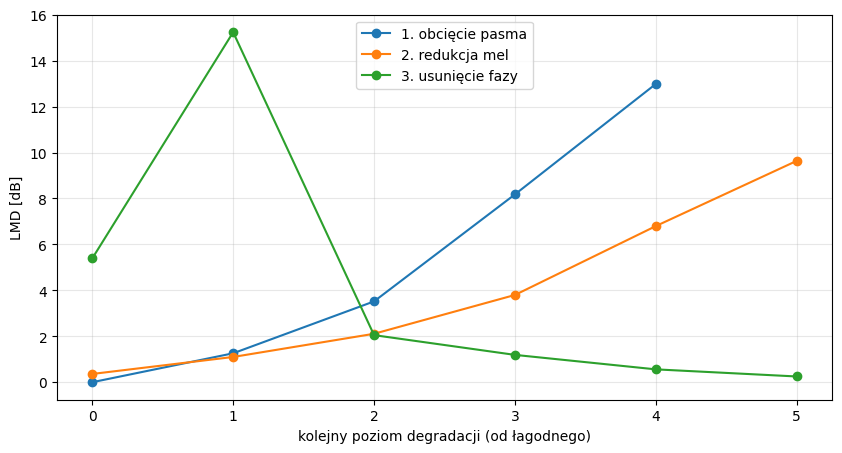

In [16]:
df = pd.DataFrame(results)
display(df)

fig, ax = plt.subplots(figsize=(10, 5))
for g, sub in df[df.degradacja != "referencja"].groupby("degradacja"):
    ax.plot(range(len(sub)), sub["LMD [dB]"], marker="o", label=g)
ax.set_xlabel("kolejny poziom degradacji (od łagodnego)"); ax.set_ylabel("LMD [dB]")
ax.legend(); ax.grid(alpha=.3); plt.show()
df.to_csv("wyniki_degradacji.csv", index=False)

### Wnioski z degradacji i odsłuchu

Obcinanie pasma zwiększało różnicę względem oryginału: LMD wzrosło z 1,26 dB przy 6 kHz do 12,99 dB przy 1 kHz. W odsłuchu nagranie wydawało się cichsze. Wynik 0,00 dB przy 8 kHz nie oznacza braku zmian, ponieważ metryka nie obejmuje częstotliwości powyżej 8 kHz.

Zmniejszanie liczby pasm mel powodowało coraz bardziej robotyczne brzmienie. LMD wzrosło z 1,10 dB dla 128 pasm do 9,64 dB dla 10 pasm, co pokazuje utratę szczegółów widma.

Zastąpienie fazy wartościami losowymi lub zerowymi wyraźnie zmieniało brzmienie. Algorytm **Griffin-Lim** stopniowo poprawiał rekonstrukcję: po 64 iteracjach LMD wyniosło 0,25 dB, a głos w odsłuchu był bardzo czysty. Nie oznacza to odzyskania oryginalnej fazy, lecz uzyskanie sygnału o zbliżonej reprezentacji widmowej.

## Weryfikacja hipotez
LMD mierzy zmianę widma, a nie zrozumiałość. Dlatego dodałem **STOI** (0–1, im wyżej tym zrozumialej) i powtórzyłem cały eksperyment na drugiej próbce (`LJ001-0003`). Przed STOI znormalizowałem RMS, żeby wyeliminować wpływ głośności. Za próg „bez dużej straty” przyjmuję roboczo STOI ≥ 0,9.

In [17]:
!pip -q install pystoi
from pystoi import stoi

In [18]:
def rms_norm(x, ref):
    return x * (np.sqrt(np.mean(ref**2)) / (np.sqrt(np.mean(x**2)) + 1e-9))

def run_all(y, name):
    rows = []
    D = librosa.stft(y, n_fft=N_FFT, hop_length=HOP)
    mag = np.abs(D)
    freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
    ref_mel = logmel(y)
    rng = np.random.default_rng(0)

    def add(group, level, x):
        x = rms_norm(x, y)
        n = min(ref_mel.shape[1], logmel(x).shape[1])
        d = float(np.mean(np.abs(ref_mel[:, :n] - logmel(x)[:, :n])))
        s = float(stoi(y, x, SR, extended=False))
        rows.append({"próbka": name, "degradacja": group, "poziom": level,
                     "LMD [dB]": round(d, 2), "STOI": round(s, 3)})

    for fc in [8000, 6000, 4000, 2000, 1000]:
        x = librosa.istft(D * (freqs <= fc)[:, None], hop_length=HOP, n_fft=N_FFT, length=len(y))
        add("1. obcięcie pasma", f"{fc} Hz", x)

    for nm in [128, 80, 40, 20, 10]:
        M = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=nm)
        x = librosa.feature.inverse.mel_to_audio(M, sr=SR, n_fft=N_FFT, hop_length=HOP, n_iter=32, length=len(y))
        add("2. redukcja mel", f"{nm} pasm", x)

    x = librosa.istft(mag * np.exp(1j * rng.uniform(-np.pi, np.pi, mag.shape)), hop_length=HOP, n_fft=N_FFT, length=len(y))
    add("3. usunięcie fazy", "faza losowa", x)
    x = librosa.istft(mag.astype(complex), hop_length=HOP, n_fft=N_FFT, length=len(y))
    add("3. usunięcie fazy", "faza zerowa", x)
    for it in [1, 4, 16, 64]:
        x = librosa.griffinlim(mag, n_iter=it, hop_length=HOP, n_fft=N_FFT, length=len(y))
        add("3. usunięcie fazy", f"Griffin-Lim {it} iter.", x)
    return rows

In [19]:
all_rows = []
for nm in ["LJ001-0001", "LJ001-0003"]:
    all_rows += run_all(signals[nm], nm)

df2 = pd.DataFrame(all_rows)
pivot = df2.pivot_table(index=["degradacja", "poziom"], columns="próbka", values=["STOI", "LMD [dB]"], sort=False)
display(pivot)
df2.to_csv("wyniki_stoi.csv", index=False)

LMD [dB]                  STOI  \
próbka                                 LJ001-0001 LJ001-0003 LJ001-0001   
degradacja        poziom                                                  
1. obcięcie pasma 8000 Hz                    0.06       0.14      1.000   
                  6000 Hz                    1.45       1.43      1.000   
                  4000 Hz                    3.70       3.43      0.995   
                  2000 Hz                    8.27       7.62      0.891   
                  1000 Hz                   12.91      12.15      0.818   
2. redukcja mel   128 pasm                   1.08       0.95      0.981   
                  80 pasm                    2.07       1.60      0.953   
                  40 pasm                    3.81       3.71      0.892   
                  20 pasm                    6.70       6.53      0.776   
                  10 pasm                    9.48       9.41      0.713   
3. usunięcie fazy faza losowa                3.38       3.18      0.852   
                  faza zerowa                4.14       4.22      0.774   
                  Griffin-Lim 1 iter.        2.02       1.99      0.922   
                  Griffin-Lim 4 iter.        1.23       1.16      0.965   
                  Griffin-Lim 16 iter.       0.56       0.56      0.993   
                  Griffin-Lim 64 iter.       0.26       0.25      0.999   

                                                   
próbka                                 LJ001-0003  
degradacja        poziom                           
1. obcięcie pasma 8000 Hz                   1.000  
                  6000 Hz                   1.000  
                  4000 Hz                   0.996  
                  2000 Hz                   0.904  
                  1000 Hz                   0.819  
2. redukcja mel   128 pasm                  0.986  
                  80 pasm                   0.953  
                  40 pasm                   0.888  
                  20 pasm                   0.753  
                  10 pasm                   0.665  
3. usunięcie fazy faza losowa               0.846  
                  faza zerowa               0.762  
                  Griffin-Lim 1 iter.       0.920  
                  Griffin-Lim 4 iter.       0.965  
                  Griffin-Lim 16 iter.      0.993  
                  Griffin-Lim 64 iter.      0.999

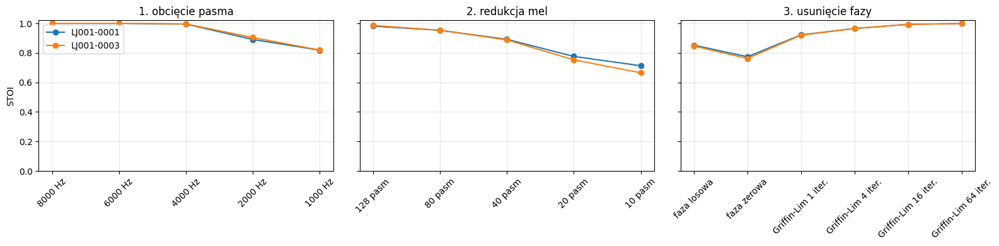

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (g, sub) in zip(axs, df2.groupby("degradacja", sort=False)):
    for nm, s in sub.groupby("próbka"):
        ax.plot(s["poziom"], s["STOI"], marker="o", label=nm)
    ax.set_title(g); ax.tick_params(axis="x", rotation=45); ax.grid(alpha=.3); ax.set_ylim(0, 1.02)
axs[0].set_ylabel("STOI"); axs[0].legend()
plt.tight_layout(); plt.show()

## Wnioski – odpowiedzi na pytania z zadania

**1. Co można wywnioskować o dźwięku?**
Mowa jednej dziewczyny (F0 ok. 234 Hz) w czystym nagraniu, z niskim szumem tła. Widać harmoniczne i formanty samogłosek, szum spółgłosek oraz pauzy.

**2. Co jest widoczne, a co nie?**
Widać intonację, formanty, granice słów i typ głoski (dźwięczna vs szum). Nie da się wiarygodnie odczytać fazy, dokładnej głoski bez kontekstu, tożsamości mówcy ani bezwzględnej głośności.

**3. Które cechy są najważniejsze?**
Obwiednia widmowa (mel/MFCC), F0 z dźwięcznością oraz rozkład energii na wysokich częstotliwościach (centroid, rolloff). Sama energia RMS słabo rozdziela rodzaje głosek.

**4. Co można usunąć, a co powinno zostać?**

| Co usunąć | Poziom bez dużej straty | STOI |
|---|---|---|
| Faza | Griffin-Lim ≥ 1 iteracja | ≥ 0,92 |
| Pasmo wysokie | do 4 kHz | ≈ 0,995 |
| Rozdzielczość mel | do 80 pasm (40 na granicy) | 0,953 (0,89) |

Najdłużej powinno zostać pasmo poniżej ok. 2 kHz oraz wystarczająca liczba pasm mel (nie mniej niż ok. 40).

**5. Jak sprawdziłem hipotezy?**
Odsłuchem każdego poziomu, dwiema metrykami (LMD i STOI), powtórzeniem na drugiej próbce oraz punktem odniesienia (Griffin-Lim z pełnego STFT).

## Ograniczenia
- Tylko dwie–trzy próbki jednej lektorki, więc wnioski mogą nie przenosić się na inne głosy ani języki.
- STOI mierzy zrozumiałość, a nie naturalność. Odsłuch jest subiektywny i wykonany przez jedną osobę.
- Próg 0,9 jest założeniem roboczym.